# Avance 3 — Explicabilidad y conclusión

**Proyecto:** Adicción a la Pantalla: detección de uso problemático en jóvenes adultos (18–35 años)
**Equipo:** Javier Andrade, Lucas Martínez, Benjamín Ramos

Este notebook continúa `modelo.ipynb` (rendimiento). Allí se compararon tres modelos sobre la misma partición 80/20 estratificada y se eligió **LightGBM** como el de mejor rendimiento (AP = 0,9845 y ROC-AUC = 0,962 en prueba). Aquí respondemos la segunda parte de la pregunta del avance: **¿cómo explica sus predicciones el modelo recomendado?**

* **Modelo explicado:** LightGBM con los mejores hiperparámetros de `modelo.ipynb`, reentrenado con todo el conjunto de entrenamiento.
* **Salida explicada:** probabilidad predicha de **uso problemático** (`addicted_label = 1`, clase positiva).
* **Herramienta:** SHAP (`TreeExplainer`), con una explicación **global** (muestra de prueba) y **locales** (3 personas de prueba).

In [1]:
import contextlib
import io
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap
from shap.plots._labels import labels as ETIQUETAS_SHAP
from pathlib import Path
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OrdinalEncoder, OneHotEncoder
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             roc_auc_score, average_precision_score)
from lightgbm import LGBMClassifier

plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False,
                     'font.size': 12, 'axes.titlesize': 13, 'axes.labelsize': 12})
FIGURAS = Path('../reports/figuras_avance3')
FIGURAS.mkdir(parents=True, exist_ok=True)
ETIQUETAS_SHAP.update({"FEATURE_VALUE_LOW": "Bajo", "FEATURE_VALUE_HIGH": "Alto"})  # leyenda del beeswarm en español

df = pd.read_csv('../data/processed/adiccion_pantalla_procesado.csv.gz')
print(f"Dimensiones: {df.shape}")

Dimensiones: (691369, 16)


## 1. Reconstrucción del modelo recomendado

Usamos **exactamente** la misma configuración de `modelo.ipynb`: las mismas 12 entradas $X$, la misma partición (80/20, estratificada, `random_state=42`), el mismo preprocesamiento ajustado solo con entrenamiento (mediana para numéricas, moda + codificación para categóricas) y los mejores hiperparámetros encontrados por `RandomizedSearchCV` (5 folds, criterio AP). Antes de explicar el modelo verificamos que sus métricas en prueba sean idénticas a las reportadas en la sección de rendimiento.

In [2]:
y_COL = "addicted_label"
NUM = ["age", "daily_screen_time_hours", "social_media_hours", "gaming_hours", "work_study_hours",
       "sleep_hours", "notifications_per_day", "app_opens_per_day", "weekend_screen_time"]
NOM = ["gender", "academic_work_impact"]
ORD = ["stress_level"]
X_COLS = NUM + NOM[:1] + ORD + NOM[1:]

X_train, X_test, y_train, y_test = train_test_split(
    df[X_COLS], df[y_COL], test_size=0.20, stratify=df[y_COL], random_state=42
)


def crear_modelo(num=NUM):
    prep = ColumnTransformer(
        transformers=[
            ("NUM", SimpleImputer(strategy="median"), num),
            ("ORD", Pipeline([("imp", SimpleImputer(strategy="most_frequent")),
                              ("enc", OrdinalEncoder(categories=[["Low", "Medium", "High"]]))]), ORD),
            ("NOM", Pipeline([("imp", SimpleImputer(strategy="most_frequent")),
                              ("enc", OneHotEncoder(drop="if_binary", handle_unknown="ignore",
                                                    sparse_output=False))]), NOM),
        ],
        verbose_feature_names_out=False,
    ).set_output(transform="pandas")
    # Mejores hiperparámetros de RandomizedSearchCV en modelo.ipynb
    clf = LGBMClassifier(n_estimators=500, learning_rate=0.1, num_leaves=31, min_child_samples=300,
                         subsample=1.0, colsample_bytree=1.0, subsample_freq=1, random_state=42, verbose=-1)
    return Pipeline([("prep", prep), ("clf", clf)])


modelo_lgbm = crear_modelo().fit(X_train, y_train)
prep, clf = modelo_lgbm.named_steps["prep"], modelo_lgbm.named_steps["clf"]

UMBRAL = 0.5
p_test = modelo_lgbm.predict_proba(X_test)[:, 1]
pred_test = (p_test >= UMBRAL).astype(int)
verificacion = pd.Series({
    "Accuracy": accuracy_score(y_test, pred_test),
    "Precision (clase 1)": precision_score(y_test, pred_test),
    "Recall (clase 1)": recall_score(y_test, pred_test),
    "Recall (clase 0)": recall_score(y_test, pred_test, pos_label=0),
    "ROC-AUC": roc_auc_score(y_test, p_test),
    "AP": average_precision_score(y_test, p_test),
}).round(4)
display(verificacion.to_frame("LightGBM (prueba)").T)

,Accuracy,Precision (clase 1),Recall (clase 1),Recall (clase 0),ROC-AUC,AP
LightGBM (prueba),0.8982,0.9241,0.9332,0.8129,0.9616,0.9845


Las métricas coinciden con la tabla de `modelo.ipynb` (accuracy 0,8982; precision 0,9241; recall 0,9332; ROC-AUC 0,9616; AP 0,9845): estamos explicando **el mismo modelo** que se evaluó en la sección de rendimiento.

## 2. Configuración de SHAP

* **Escala de la explicación: probabilidad.** Usamos `TreeExplainer` en modo *interventional* con `model_output="probability"`. Así, cada valor SHAP se lee en **puntos porcentuales de probabilidad de uso problemático**, y se cumple:

$$\underbrace{\mathbb{E}[f(X)]}_{\text{valor base}} + \sum_j \phi_j(x) = \underbrace{f(x)}_{\text{probabilidad predicha}}$$

* **Datos de referencia (fondo):** 1.000 personas del conjunto de **entrenamiento** (muestra aleatoria, `random_state=42`). El valor base es la probabilidad promedio que el modelo asigna a ese fondo.
* **Muestra explicada (global):** 2.000 personas del conjunto de **prueba** (muestra aleatoria, `random_state=42`), no usadas para entrenar.
* **Variables:** SHAP se calcula sobre las entradas que ve el modelo (después de imputar y codificar). Las tres columnas *one-hot* de género se suman en una sola variable **Género** (los valores SHAP son aditivos, por lo que la suma es la contribución total del género).

In [3]:
NOMBRES = {
    "age": "Edad", "daily_screen_time_hours": "Pantalla diaria (h)", "social_media_hours": "Redes sociales (h)",
    "gaming_hours": "Videojuegos (h)", "work_study_hours": "Trabajo/estudio (h)", "sleep_hours": "Sueño (h)",
    "notifications_per_day": "Notificaciones/día", "app_opens_per_day": "Aperturas de apps/día",
    "weekend_screen_time": "Pantalla fin de semana (h)", "stress_level": "Nivel de estrés",
    "gender": "Género", "academic_work_impact": "Impacto académico/laboral",
}
TRADUCCION = {"Male": "Hombre", "Female": "Mujer", "Other": "Otro", "Low": "Bajo", "Medium": "Medio",
              "High": "Alto", "No": "No", "Yes": "Sí"}
COLS_GENERO = ["gender_Female", "gender_Male", "gender_Other"]

fondo = prep.transform(X_train.sample(1000, random_state=42))
explicador = shap.TreeExplainer(clf, data=shap.maskers.Independent(fondo, max_samples=1000),
                                model_output="probability")


def explicar(X_crudo):
    # Valores SHAP (probabilidad) agrupando el género y con nombres legibles
    Xt = prep.transform(X_crudo)
    with contextlib.redirect_stderr(io.StringIO()):  # oculta la barra de progreso de SHAP
        e = explicador(Xt)
    sv = pd.DataFrame(e.values, index=Xt.index, columns=Xt.columns)
    sv["gender"] = sv[COLS_GENERO].sum(axis=1)
    sv = sv.drop(columns=COLS_GENERO).rename(columns={"academic_work_impact_Yes": "academic_work_impact"})
    datos = Xt.drop(columns=COLS_GENERO).rename(columns={"academic_work_impact_Yes": "academic_work_impact"})
    datos["gender"] = np.nan  # categórica sin orden: se muestra en gris en el beeswarm
    orden = list(NOMBRES)
    return shap.Explanation(values=sv[orden].to_numpy(), base_values=e.base_values,
                            data=datos[orden].to_numpy(), feature_names=[NOMBRES[c] for c in orden]), Xt


muestra = X_test.sample(2000, random_state=42)
exp_global, Xt_muestra = explicar(muestra)

p_muestra = clf.predict_proba(Xt_muestra)[:, 1]
print(f"Valor base E[f(X)] = {exp_global.base_values[0]:.3f} (probabilidad promedio predicha en el fondo)")
print(f"Muestra global: {len(muestra):,} personas de prueba | prevalencia Y=1 = {y_test.loc[muestra.index].mean():.3f} | "
      f"AP en la muestra = {average_precision_score(y_test.loc[muestra.index], p_muestra):.4f}")
error_aditividad = np.abs(exp_global.base_values + exp_global.values.sum(axis=1) - p_muestra).max()
print(f"Verificación de aditividad (base + suma SHAP = probabilidad): error máximo = {error_aditividad:.1e}")

Valor base E[f(X)] = 0.690 (probabilidad promedio predicha en el fondo)
Muestra global: 2,000 personas de prueba | prevalencia Y=1 = 0.719 | AP en la muestra = 0.9862
Verificación de aditividad (base + suma SHAP = probabilidad): error máximo = 1.2e-08


## 3. Explicación global

### 3.1 ¿Qué variables influyen más y en qué dirección?

El gráfico *beeswarm* muestra un punto por persona y variable: la posición horizontal es el valor SHAP (cuánto sube o baja la probabilidad de uso problemático respecto del valor base) y el color es el valor de la variable (rojo = alto, azul = bajo). Las variables están ordenadas por la media de |SHAP|.

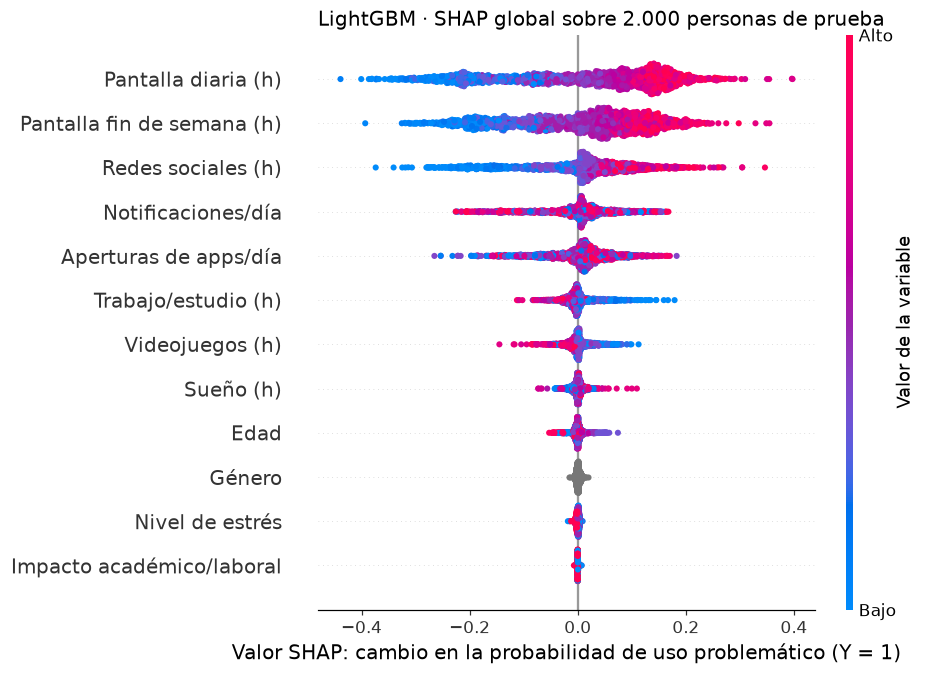

,media |SHAP| (p.p.),% del total
Pantalla diaria (h),12.97,29.46
Pantalla fin de semana (h),10.17,23.10
Redes sociales (h),7.31,16.61
Notificaciones/día,4.31,9.78
Aperturas de apps/día,4.09,9.30
Trabajo/estudio (h),1.76,4.01
Videojuegos (h),1.50,3.42
Sueño (h),0.74,1.69
Edad,0.70,1.59
Género,0.24,0.54


,% de la importancia total
"Hábitos de uso (pantalla diaria, fin de semana, redes, videojuegos, trabajo/estudio)",76.6
Notificaciones y aperturas de apps,19.1
"Contexto personal y sueño (edad, sueño, estrés, género, impacto)",4.3


In [4]:
plt.figure()
with warnings.catch_warnings():
    warnings.simplefilter("ignore", RuntimeWarning)  # Género no tiene valor numérico (se dibuja en gris)
    shap.plots.beeswarm(exp_global, max_display=12, show=False, plot_size=(8.8, 6.3),
                        color_bar_label="Valor de la variable")
ax = plt.gca()
ax.set_xlabel("Valor SHAP: cambio en la probabilidad de uso problemático (Y = 1)")
ax.set_title("LightGBM · SHAP global sobre 2.000 personas de prueba", fontsize=13, loc="left")
plt.tight_layout()
plt.savefig(FIGURAS / "shap_global_beeswarm.png", dpi=200, bbox_inches="tight")
plt.show()

importancia = pd.Series(np.abs(exp_global.values).mean(axis=0), index=exp_global.feature_names)
grupos = {
    "Hábitos de uso (pantalla diaria, fin de semana, redes, videojuegos, trabajo/estudio)":
        ["Pantalla diaria (h)", "Pantalla fin de semana (h)", "Redes sociales (h)", "Videojuegos (h)", "Trabajo/estudio (h)"],
    "Notificaciones y aperturas de apps": ["Notificaciones/día", "Aperturas de apps/día"],
    "Contexto personal y sueño (edad, sueño, estrés, género, impacto)":
        ["Edad", "Sueño (h)", "Nivel de estrés", "Género", "Impacto académico/laboral"],
}
resumen = pd.DataFrame({
    "media |SHAP| (p.p.)": importancia.sort_values(ascending=False) * 100,
    "% del total": importancia.sort_values(ascending=False) / importancia.sum() * 100,
}).round(2)
display(resumen)
display(pd.Series({g: importancia[v].sum() / importancia.sum() * 100 for g, v in grupos.items()},
                  name="% de la importancia total").round(1).to_frame())

### 3.2 Forma de las relaciones principales (gráficos de dependencia)

Para leer la **dirección** y la **forma** de los efectos, graficamos el valor SHAP de una variable contra su valor. Si el modelo reproduce el efecto umbral del EDA, la nube debería tener forma de "S".

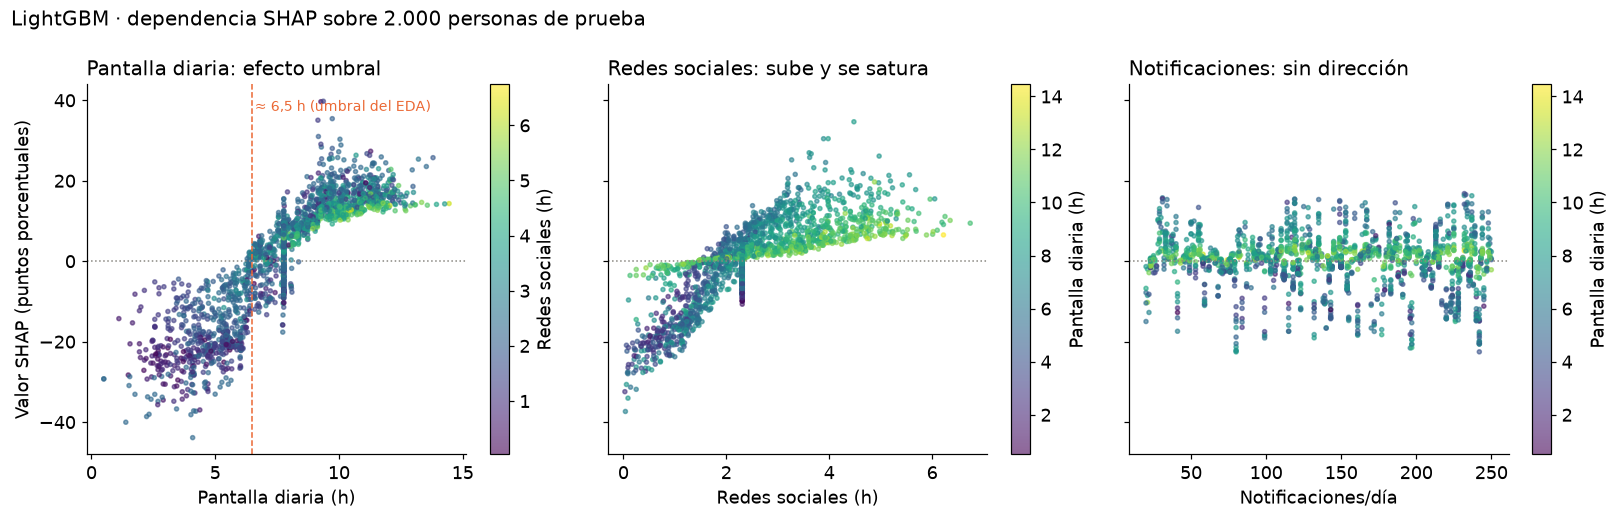

x,"(0.0, 4.0]","(4.0, 5.0]","(5.0, 6.0]","(6.0, 6.5]","(6.5, 7.0]","(7.0, 8.0]","(8.0, 10.0]","(10.0, 16.0]"
SHAP medio de pantalla diaria (p.p.),-21.5,-20.5,-15.7,-10.7,-0.6,2.1,12.6,16.1


In [5]:
idx = {n: i for i, n in enumerate(exp_global.feature_names)}
paneles = [
    ("Pantalla diaria (h)", "Redes sociales (h)", "Pantalla diaria: efecto umbral"),
    ("Redes sociales (h)", "Pantalla diaria (h)", "Redes sociales: sube y se satura"),
    ("Notificaciones/día", "Pantalla diaria (h)", "Notificaciones: sin dirección"),
]
fig, axes = plt.subplots(1, 3, figsize=(15, 4.8), sharey=True)
for ax, (var, color_var, titulo) in zip(axes, paneles):
    puntos = ax.scatter(exp_global.data[:, idx[var]], exp_global.values[:, idx[var]] * 100,
                        c=exp_global.data[:, idx[color_var]], cmap="viridis", s=7, alpha=0.6)
    ax.axhline(0, color="#898781", lw=1, ls=":")
    ax.set_xlabel(var)
    ax.set_title(titulo, loc="left")
    fig.colorbar(puntos, ax=ax, label=color_var)
axes[0].set_ylabel("Valor SHAP (puntos porcentuales)")
axes[0].axvline(6.5, color="#eb6834", lw=1, ls="--")
axes[0].text(6.6, axes[0].get_ylim()[1] * 0.85, "≈ 6,5 h (umbral del EDA)", color="#eb6834", fontsize=9)
plt.suptitle("LightGBM · dependencia SHAP sobre 2.000 personas de prueba", x=0.01, ha="left", fontsize=13)
plt.tight_layout()
plt.savefig(FIGURAS / "shap_dependencia.png", dpi=200, bbox_inches="tight")
plt.show()

# Rango de valores donde la contribución de la pantalla diaria cambia de signo
pantalla = pd.DataFrame({"x": exp_global.data[:, idx["Pantalla diaria (h)"]],
                         "shap": exp_global.values[:, idx["Pantalla diaria (h)"]]})
tramos = pantalla.groupby(pd.cut(pantalla["x"], [0, 4, 5, 6, 6.5, 7, 8, 10, 16]), observed=True)["shap"].mean() * 100
display(tramos.round(1).to_frame("SHAP medio de pantalla diaria (p.p.)").T)

In [6]:
# Dirección de trabajo/estudio y videojuegos: SHAP medio por tramo
for var, bordes in [("Trabajo/estudio (h)", [0, 1, 2, 3, 4, 6]), ("Videojuegos (h)", [0, 0.5, 1, 2, 3, 4])]:
    x = pd.Series(exp_global.data[:, idx[var]])
    s = pd.Series(exp_global.values[:, idx[var]] * 100)
    display(s.groupby(pd.cut(x, bordes, include_lowest=True), observed=True).mean().round(1)
             .to_frame(f"SHAP medio de {var} (p.p.)").T)

# Personas con pantalla diaria faltante: el modelo ve la mediana imputada (7,77 h)
imputados = muestra["daily_screen_time_hours"].isna().to_numpy()
s_imp = exp_global.values[imputados, idx["Pantalla diaria (h)"]] * 100
print(f"Pantalla diaria imputada en {imputados.mean():.1%} de la muestra; "
      f"todas tienen el mismo valor (7,77 h) pero su contribución va de {s_imp.min():.1f} a {s_imp.max():.1f} p.p.")

,"(-0.001, 1.0]","(1.0, 2.0]","(2.0, 3.0]","(3.0, 4.0]","(4.0, 6.0]"
SHAP medio de Trabajo/estudio (h) (p.p.),2.7,1.2,-0.2,-1.6,-1.5


,"(-0.001, 0.5]","(0.5, 1.0]","(1.0, 2.0]","(2.0, 3.0]","(3.0, 4.0]"
SHAP medio de Videojuegos (h) (p.p.),1.0,1.6,0.3,-1.9,-1.7


Pantalla diaria imputada en 14.6% de la muestra; todas tienen el mismo valor (7,77 h) pero su contribución va de -11.5 a 15.5 p.p.


**Interpretación global**

* **El modelo se apoya principalmente en los hábitos de uso (77 % de la importancia).** Pantalla diaria (29 %), pantalla de fin de semana (23 %) y redes sociales (17 %) son las tres variables más influyentes, en el mismo orden que en el EDA (AUC univariado 0,89 / 0,88 / 0,86). **Dirección:** valores altos (rojo) aumentan la probabilidad de uso problemático y valores bajos (azul) la reducen.
* **Pantalla diaria reproduce el efecto umbral del EDA (H3).** Su contribución media es de −21 p.p. con menos de 4 h, cambia de signo entre **6,5 y 7 h** y llega a +16 p.p. sobre 10 h: es la misma curva en S del EDA, que cruzaba el 50 % cerca de las 6,5 h. El modelo aprendió una relación **no lineal** que un modelo lineal no captaría.
* **Redes sociales interactúa con el tiempo total.** Su contribución sube hasta ≈ 3 h y luego se satura, y es mayor cuando la pantalla total es baja o media (puntos morados y azules en el gráfico central) que cuando ya es alta (puntos amarillos). Es la interacción pantalla × redes observada en el EDA.
* **Hallazgo nuevo: trabajo/estudio y videojuegos tienen dirección inversa.** En el EDA, por sí solas, se asociaban positivamente con $Y$ (porque suben junto con el tiempo total). Pero, **a igual tiempo total de pantalla**, más horas de trabajo/estudio reducen la probabilidad (de +2,7 p.p. con ≤ 1 h a −1,6 p.p. con 3–4 h), y lo mismo ocurre con los videojuegos sobre 2 h. El modelo distingue *en qué* se usa la pantalla: el riesgo está en el tiempo de ocio y redes, no en el tiempo productivo.
* **Notificaciones y aperturas pesan un 19 %, pero sin dirección.** En el beeswarm los colores están mezclados y, en el gráfico de dependencia, cada valor exacto forma una franja vertical sin tendencia. Es la "huella" del EDA (sección 3.4.4): el modelo usa los valores exactos como identificadores de perfiles, no porque más notificaciones signifiquen más riesgo.
* **El contexto personal y el sueño casi no influyen (4 % en total).** Edad, sueño, estrés, género e impacto académico/laboral tienen contribuciones cercanas a 0, lo que confirma el hallazgo H4 del EDA.

## 4. Explicaciones locales

### 4.1 Selección de los casos

Elegimos tres personas del conjunto de **prueba** con criterios explícitos y reproducibles. Para que la explicación no dependa de valores imputados, solo consideramos personas **sin datos faltantes** (39 % del conjunto de prueba). Dentro de cada grupo tomamos a la persona cuya probabilidad predicha está más cerca de la **mediana del grupo** (un caso típico, no un extremo):

| Caso | Tipo | Criterio | Por qué es relevante |
|---|---|---|---|
| **1** | Acierto (verdadero positivo) | Y = 1, predicho 1, pantalla diaria 4–6 h y redes sociales ≥ 3 h | Está **bajo** el umbral de pantalla: el modelo debe usar otra señal para acertar |
| **2** | Error relevante (falso negativo) | Y = 1, predicho 0, pantalla diaria 4–6 h | El error más costoso para el problema: una persona con uso problemático que **no** recibiría la intervención. La zona 4–6 h concentra los falsos negativos |
| **3** | Contraste (verdadero positivo con certeza) | Y = 1, predicho 1, pantalla diaria ≥ 10 h | Caso "fácil" sobre el umbral, para contrastar cómo cambia la explicación |

In [7]:
d = X_test.copy()
d["y"], d["p"], d["pred"] = y_test.values, p_test, pred_test
completos = d[X_test.notna().all(axis=1)]
pantalla_d = completos["daily_screen_time_hours"]

grupos_casos = {
    "Caso 1 · Acierto": completos[(completos.y == 1) & (completos.pred == 1) & pantalla_d.between(4, 6, inclusive="left")
                                  & (completos.social_media_hours >= 3)],
    "Caso 2 · Error (falso negativo)": completos[(completos.y == 1) & (completos.pred == 0)
                                                 & pantalla_d.between(4, 6, inclusive="left")],
    "Caso 3 · Contraste (≥ 10 h)": completos[(completos.y == 1) & (completos.pred == 1) & (pantalla_d >= 10)],
}
casos = {}
for nombre, g in grupos_casos.items():
    elegido = (g["p"] - g["p"].median()).abs().idxmin()
    casos[nombre] = elegido
    print(f"{nombre}: {len(g):,} candidatos | p mediana del grupo = {g['p'].median():.3f} | elegido: fila {elegido}")

tabla_casos = d.loc[list(casos.values()), X_COLS + ["y", "p", "pred"]].copy()
tabla_casos.index = list(casos)
for col in ["gender", "stress_level", "academic_work_impact"]:
    tabla_casos[col] = tabla_casos[col].map(TRADUCCION)
tabla_casos = tabla_casos.rename(columns={**NOMBRES, "y": "Y real", "p": "Prob. predicha", "pred": "Predicción (umbral 0,5)"})
display(tabla_casos.T)

Caso 1 · Acierto: 330 candidatos | p mediana del grupo = 0.894 | elegido: fila 320890
Caso 2 · Error (falso negativo): 1,000 candidatos | p mediana del grupo = 0.323 | elegido: fila 86104
Caso 3 · Contraste (≥ 10 h): 12,407 candidatos | p mediana del grupo = 1.000 | elegido: fila 509325


,Caso 1 · Acierto,Caso 2 · Error (falso negativo),Caso 3 · Contraste (≥ 10 h)
Edad,31.0,18.0,18.0
Pantalla diaria (h),5.27,5.86,11.73
Redes sociales (h),3.71,1.36,5.19
Videojuegos (h),0.09,1.27,2.16
Trabajo/estudio (h),1.06,2.36,2.71
Sueño (h),7.04,4.66,7.95
Notificaciones/día,112.0,237.0,195.0
Aperturas de apps/día,66.0,80.0,168.0
Pantalla fin de semana (h),7.9,8.11,10.4
Género,Mujer,Hombre,Hombre


### 4.2 Gráficos *waterfall*

Cada gráfico parte del **valor base** $\mathbb{E}[f(X)]$ (abajo) y suma las contribuciones de cada variable hasta llegar a la **probabilidad predicha** $f(x)$ (arriba). Las barras rojas aumentan la probabilidad de uso problemático y las azules la reducen. Junto a cada variable se muestra su valor real para esa persona.

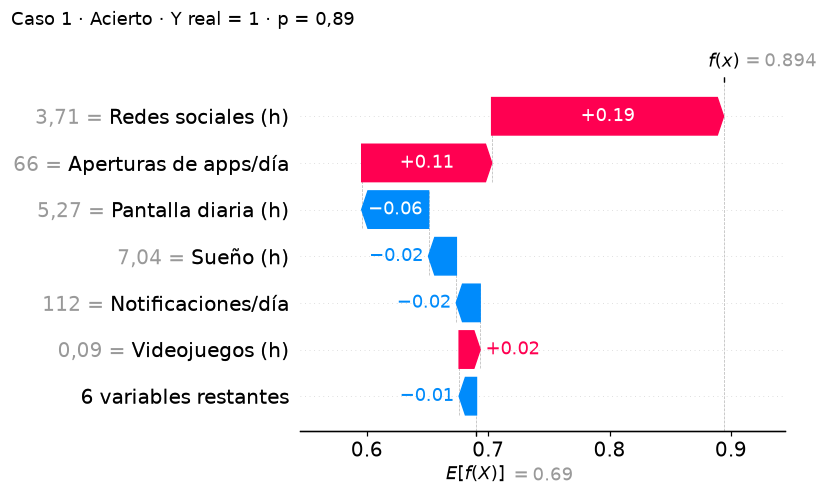

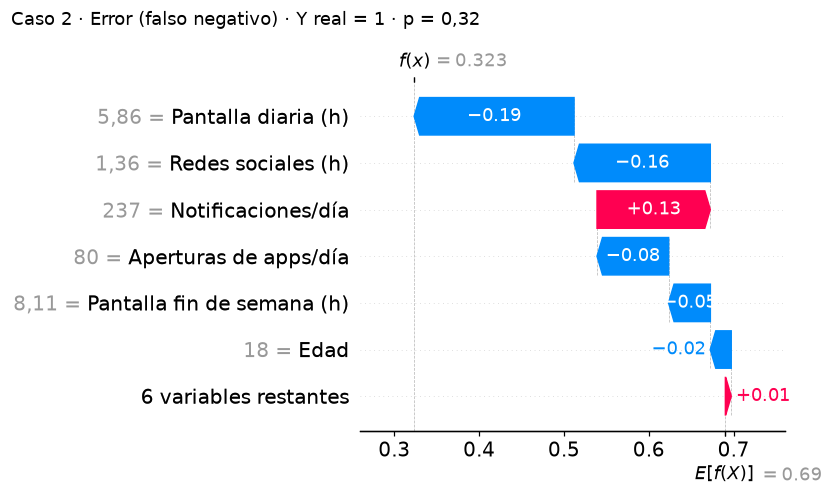

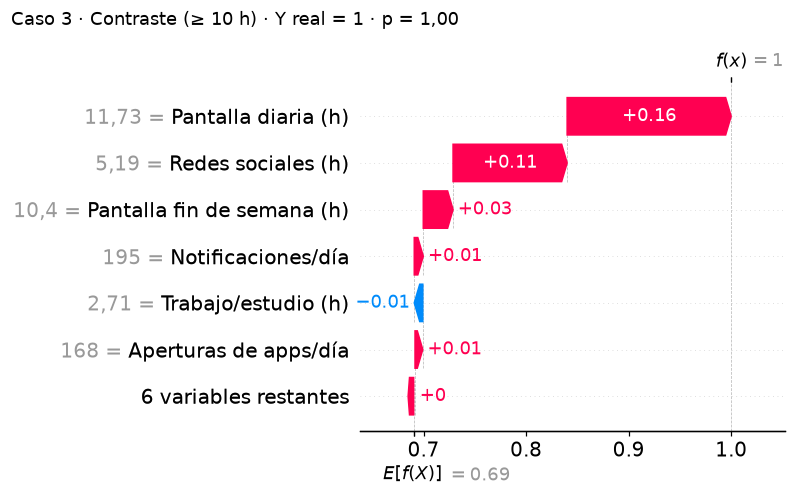

In [8]:
exp_casos, _ = explicar(X_test.loc[list(casos.values())])
# Para los gráficos se muestran los valores originales (sin codificar)
crudos = X_test.loc[list(casos.values()), list(NOMBRES)]
def mostrar(v):
    return TRADUCCION.get(v, v) if isinstance(v, str) else f"{v:g}".replace(".", ",")


exp_casos.display_data = crudos.apply(lambda col: col.map(mostrar)).to_numpy()

archivos = ["shap_local_caso1_acierto.png", "shap_local_caso2_error.png", "shap_local_caso3_contraste.png"]
for i, (nombre, fila) in enumerate(casos.items()):
    plt.figure()
    shap.plots.waterfall(exp_casos[i], max_display=7, show=False)
    fig = plt.gcf()
    fig.set_size_inches(8, 4.6)
    ax = plt.gca()
    formato = ax.yaxis.get_major_formatter()
    original = formato.func
    formato.func = lambda x, pos=None, f=original: f(x, pos).replace("other features", "variables restantes")
    plt.tight_layout()
    fig.subplots_adjust(top=0.84, right=0.9)
    fig.suptitle(f"{nombre} · Y real = {d.loc[fila, 'y']} · p = {d.loc[fila, 'p']:.2f}".replace(".", ","),
                 x=0.02, ha="left", fontsize=12)
    plt.savefig(FIGURAS / archivos[i], dpi=200)  # lienzo fijo: los tres casos quedan del mismo tamaño
    plt.show()

In [9]:
# Resumen comparable de los tres casos
filas = []
for i, (nombre, fila) in enumerate(casos.items()):
    contrib = pd.Series(exp_casos.values[i], index=exp_casos.feature_names)
    na = contrib[["Notificaciones/día", "Aperturas de apps/día"]].sum()
    sube = contrib[contrib > 0].sort_values(ascending=False).head(2)
    baja = contrib[contrib < 0].sort_values().head(2)
    filas.append({
        "Caso": nombre,
        "Y real": int(d.loc[fila, "y"]),
        "Valor base": exp_casos.base_values[i],
        "Prob. predicha": d.loc[fila, "p"],
        "Principales a favor de Y=1": ", ".join(f"{k} (+{v * 100:.1f})" for k, v in sube.items()),
        "Principales en contra de Y=1": ", ".join(f"{k} ({v * 100:.1f})" for k, v in baja.items()),
        "Notif. + aperturas (p.p.)": na * 100,
        "Prob. sin notif. + aperturas": d.loc[fila, "p"] - na,
    })
resumen_casos = pd.DataFrame(filas).set_index("Caso")
display(resumen_casos.round(3))

,Y real,Valor base,Prob. predicha,Principales a favor de Y=1,Principales en contra de Y=1,Notif. + aperturas (p.p.),Prob. sin notif. + aperturas
Caso,,,,,,,
Caso 1 · Acierto,1,0.69,0.894,"Redes sociales (h) (+19.1), Aperturas de apps/...","Pantalla diaria (h) (-5.5), Sueño (h) (-2.3)",8.746,0.806
Caso 2 · Error (falso negativo),1,0.69,0.323,"Notificaciones/día (+13.3), Videojuegos (h) (+...","Pantalla diaria (h) (-18.8), Redes sociales (h...",4.910,0.274
Caso 3 · Contraste (≥ 10 h),1,0.69,1.000,"Pantalla diaria (h) (+16.0), Redes sociales (h...","Trabajo/estudio (h) (-0.8), Edad (-0.4)",1.634,0.984


**Interpretación de los casos**

Los tres parten del mismo valor base, **0,69**: la probabilidad promedio que el modelo asigna a la población de entrenamiento.

* **Caso 1 · Acierto (real Y = 1, p = 0,89).** Mujer de 31 años con **5,3 h** de pantalla diaria, es decir, *bajo* el umbral; por eso la pantalla le resta 5,5 p.p. Lo que decide la predicción son sus **3,7 h de redes sociales (+19 p.p.)**. Es la interacción del EDA: en ese perfil (4–6 h de pantalla y 3–4 h de redes) el 79 % tiene uso problemático. Las aperturas de apps suman +11 p.p. por el efecto "huella". Sin notificaciones ni aperturas la probabilidad sería ≈ 0,81, así que el acierto no depende de ellas.
* **Caso 2 · Error, falso negativo (real Y = 1, p = 0,32).** Hombre de 18 años con **5,9 h** de pantalla (−19 p.p.) y solo **1,4 h de redes sociales (−16 p.p.)**. Según los patrones que aprendió el modelo, su perfil corresponde al de "sin uso problemático". En el EDA, de las personas con 4–6 h de pantalla y 1–2 h de redes, solo el **28 %** tiene uso problemático, y el modelo le asigna 32 %: la probabilidad es coherente con su grupo, pero esta persona pertenece a la minoría. Con umbral 0,5, todo ese grupo se clasifica como 0. Además duerme solo **4,7 h**, y el sueño no aporta nada a la predicción (el modelo no lo usa, coherente con el EDA). Es el error más costoso para el problema: una persona con uso problemático que **no** recibiría la intervención.
* **Caso 3 · Contraste (real Y = 1, p = 1,00).** Con **11,7 h** de pantalla (+16 p.p.) y **5,2 h** de redes (+11 p.p.), la explicación se concentra en dos variables y el resto es irrelevante. Sobre 10 h el modelo casi no se equivoca (error ≈ 0,1 % en `modelo.ipynb`).

**Comparación:** los casos 1 y 2 tienen casi el mismo tiempo de pantalla (5,3 h y 5,9 h) y aun así terminan en lados opuestos del umbral. La diferencia la hacen las **redes sociales**: +19 p.p. en un caso y −16 p.p. en el otro, unos 35 p.p. de distancia. Los errores se concentran en esta zona intermedia, donde la decisión depende de varias variables a la vez. En cambio, sobre el umbral (caso 3) la decisión es simple y segura.

## 5. Limitación detectada y mejora propuesta: el modelo sin notificaciones ni aperturas

El EDA (sección 3.4.4) mostró que notificaciones y aperturas **no tienen relación monótona con $Y$**, pero cada valor exacto funciona como una "huella" del perfil de uso, probablemente un artefacto de la generación sintética del dataset. SHAP confirma que el modelo usa esas variables. Para cuantificar cuánto depende de ellas, reentrenamos LightGBM **sin** esas dos variables (mismos hiperparámetros) y lo evaluamos con la **misma validación cruzada de 5 folds sobre entrenamiento** usada en `modelo.ipynb`. No se usa el conjunto de prueba, porque esta comparación sirve para decidir.

In [10]:
# ¿En cuántas decisiones influye la "huella" de notificaciones y aperturas? (aproximación con SHAP)
contrib_na = exp_global.values[:, [idx["Notificaciones/día"], idx["Aperturas de apps/día"]]].sum(axis=1)
p_sin_na = p_muestra - contrib_na
cambia = (p_muestra >= UMBRAL) != (p_sin_na >= UMBRAL)
acierta = (p_muestra >= UMBRAL).astype(int) == y_test.loc[muestra.index].to_numpy()
print(f"Notificaciones + aperturas mueven la probabilidad en {np.abs(contrib_na).mean() * 100:.1f} p.p. en promedio")
print(f"Cambian la decisión (cruzan el umbral 0,5) en {cambia.mean():.1%} de las 2.000 personas; "
      f"en esos casos el modelo acierta el {acierta[cambia].mean():.0%} de las veces")

Notificaciones + aperturas mueven la probabilidad en 6.8 p.p. en promedio
Cambian la decisión (cruzan el umbral 0,5) en 3.0% de las 2.000 personas; en esos casos el modelo acierta el 75% de las veces


In [11]:
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.metrics import make_scorer

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)   # mismas particiones que modelo.ipynb
SCORING = {"accuracy": "accuracy", "precision": "precision", "recall": "recall",
           "recall_clase0": make_scorer(recall_score, pos_label=0), "roc_auc": "roc_auc",
           "ap": "average_precision"}
NUM_SIN = [c for c in NUM if c not in ("notifications_per_day", "app_opens_per_day")]

variantes = {
    "LightGBM (12 variables)": (crear_modelo(NUM), X_COLS),
    "LightGBM sin notificaciones ni aperturas": (crear_modelo(NUM_SIN), NUM_SIN + NOM[:1] + ORD + NOM[1:]),
}
filas = []
for nombre, (m, cols) in variantes.items():
    r = cross_validate(m, X_train[cols], y_train, cv=skf, scoring=SCORING, return_train_score=True, n_jobs=1)
    for met in SCORING:
        filas.append({"Modelo": nombre, "Métrica": met, "Train": r[f"train_{met}"].mean(),
                      "Validación (media)": r[f"test_{met}"].mean(), "Validación (desv.)": r[f"test_{met}"].std()})
sensibilidad = pd.DataFrame(filas).pivot(index="Métrica", columns="Modelo", values="Validación (media)")
sensibilidad["Diferencia"] = sensibilidad.iloc[:, 1] - sensibilidad.iloc[:, 0]
display(sensibilidad.round(4))
display(pd.DataFrame(filas).round(4))

Modelo,LightGBM (12 variables),LightGBM sin notificaciones ni aperturas,Diferencia
Métrica,,,
accuracy,0.8999,0.8710,-0.0289
ap,0.9848,0.9772,-0.0076
precision,0.9251,0.8996,-0.0255
recall,0.9347,0.9210,-0.0137
recall_clase0,0.8152,0.7490,-0.0662
roc_auc,0.9623,0.9435,-0.0188


,Modelo,Métrica,Train,Validación (media),Validación (desv.)
0,LightGBM (12 variables),accuracy,0.9066,0.8999,0.0013
1,LightGBM (12 variables),precision,0.9298,0.9251,0.0015
2,LightGBM (12 variables),recall,0.9392,0.9347,0.0007
3,LightGBM (12 variables),recall_clase0,0.8268,0.8152,0.0040
4,LightGBM (12 variables),roc_auc,0.9672,0.9623,0.0007
5,LightGBM (12 variables),ap,0.9869,0.9848,0.0003
6,LightGBM sin notificaciones ni aperturas,accuracy,0.8787,0.8710,0.0005
7,LightGBM sin notificaciones ni aperturas,precision,0.9050,0.8996,0.0011
8,LightGBM sin notificaciones ni aperturas,recall,0.9262,0.9210,0.0014
9,LightGBM sin notificaciones ni aperturas,recall_clase0,0.7627,0.7490,0.0034


**Interpretación de la sensibilidad**

* Según SHAP, notificaciones y aperturas mueven la probabilidad en 6,8 p.p. en promedio y **cambian la decisión en el 3 %** de las personas de la muestra; en esos casos el modelo acierta el 75 % de las veces. En este dataset, la "huella" **mejora** el rendimiento.
* Al reentrenar sin ellas, el modelo pierde **0,008 de AP** (0,9848 → 0,9772) y **6,6 p.p. de recall de la clase 0** (0,815 → 0,749), con la misma validación cruzada. La mayor parte del rendimiento viene de los hábitos de uso.
* Incluso sin esas dos variables, LightGBM supera a la regresión logística evaluada en `modelo.ipynb` con todas las variables (validación cruzada: AP 0,9772 vs 0,9689; ROC-AUC 0,944 vs 0,922; recall de la clase 0 0,749 vs 0,717). La ventaja de LightGBM **no depende** del artefacto.
* La diferencia entre entrenamiento y validación sigue siendo pequeña (AP 0,980 vs 0,977): no hay señales de sobreajuste.

## 6. Limitaciones de la interpretación

1. **SHAP explica al modelo, no a las personas.** Que las redes sociales aumenten la probabilidad predicha no demuestra que reducirlas disminuya el uso problemático: no es una relación causal.
2. **Variables correlacionadas comparten el crédito.** Pantalla diaria y de fin de semana tienen r = 0,80; parte del 23 % atribuido al fin de semana podría corresponder a la pantalla diaria, y viceversa.
3. **Se explican valores imputados.** El 14,6 % de la muestra no tenía pantalla diaria y el modelo vio la mediana (7,77 h). Esas personas forman la franja vertical del gráfico de dependencia, con contribuciones de −11,5 a +15,5 p.p. para un mismo valor que no es real. Por eso los casos locales se eligieron entre personas sin datos faltantes.
4. **La explicación depende de la referencia.** El valor base y las contribuciones se calculan respecto de 1.000 personas de entrenamiento, y la vista global se basa en una muestra de 2.000 personas de prueba.
5. **El modelo refleja los artefactos del dataset.** La importancia de notificaciones y aperturas, y probablemente el peso dominante de la pantalla diaria (posible circularidad de la etiqueta detectada en el EDA), podrían no repetirse con datos reales.

## 7. Conclusión y decisión

**Modelo recomendado: LightGBM.**

| Evidencia | Regla simple | Regresión logística | **LightGBM** |
|---|---|---|---|
| AP (prueba) | 0,920 | 0,968 | **0,984** |
| ROC-AUC (prueba) | 0,867 | 0,920 | **0,962** |
| Accuracy (prueba, umbral 0,5) | 0,805 | 0,841 | **0,898** |
| Recall clase 1 / clase 0 (prueba) | 0,971 / 0,402 | 0,891 / 0,718 | **0,933 / 0,813** |
| AP entrenamiento vs prueba | 0,920 / 0,920 | 0,969 / 0,968 | 0,987 / 0,985 |

* **Rendimiento:** es el mejor en todas las métricas resumen y es el único que reconoce bien a quienes *no* tienen uso problemático (recall de la clase 0 = 0,81; la regla simple marca como "problemático" a 6 de cada 10 de ellos). Su diferencia entre entrenamiento y prueba es mínima.
* **Explicabilidad:** sus explicaciones son coherentes con el EDA. Aprendió el umbral de ≈ 6,5 h de pantalla, la interacción con las redes sociales y la poca relevancia del contexto personal. Además distingue tiempo de ocio de tiempo productivo.

**Limitación principal:** cerca del **19 %** de la importancia del modelo proviene de notificaciones y aperturas, cuyos valores exactos funcionan como una huella de perfiles, probablemente un artefacto de la generación sintética del dataset. Ayuda en este dataset, pero difícilmente se repetiría con datos reales.

**Mejora propuesta:** para usar el modelo fuera de este dataset, entrenar **LightGBM sin notificaciones ni aperturas**. Pierde poco (AP 0,977 en validación cruzada) y sigue superando a la regresión logística. Después conviene validarlo con datos reales y ajustar el umbral con validación cruzada según el costo de cada error: como la intervención es breve, un falso negativo cuesta más que un falso positivo.

**Respuesta a la pregunta del proyecto:** sí, es posible identificar el uso problemático de pantallas a partir de los hábitos digitales de una semana típica (ROC-AUC 0,96). La decisión se basa principalmente en **cuánto** se usa la pantalla y **en qué** (redes sociales), y no en el contexto personal ni en el sueño.